In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.axes._axes import _log as matplotlib_axes_logger
from mpl_toolkits import mplot3d
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_circles

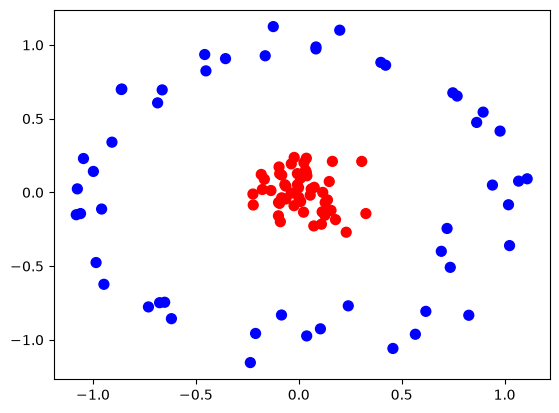

In [12]:
X, y = make_circles(100, factor=.1, noise=.1)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='bwr')

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20)

In [14]:
classifier = SVC(kernel="linear")
classifier.fit(X_train, y_train.ravel())
y_pred = classifier.predict(X_test)

In [15]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.55

In [30]:
zero_one_colourmap = ListedColormap(('blue', 'red'))
def plot_decision_boundary(X, y, clf):
    X_set, y_set = X, y
    X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, 
                                 stop = X_set[:, 0].max() + 1, 
                                 step = 0.01),
                       np.arange(start = X_set[:, 1].min() - 1, 
                                 stop = X_set[:, 1].max() + 1, 
                                 step = 0.01))
  
    plt.contourf(X1, X2, clf.predict(np.array([X1.ravel(), 
                                             X2.ravel()]).T).reshape(X1.shape),
               alpha = 0.75, 
               cmap = zero_one_colourmap)
    plt.xlim(X1.min(), X1.max())
    plt.ylim(X2.min(), X2.max())
    for i, j in enumerate(np.unique(y_set)):
        plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = (zero_one_colourmap)(i), label = j)
    plt.title('SVM Decision Boundary')
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.legend()
    return plt.show()

C:\Users\jaggi\AppData\Local\Temp\ipykernel_12116\3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


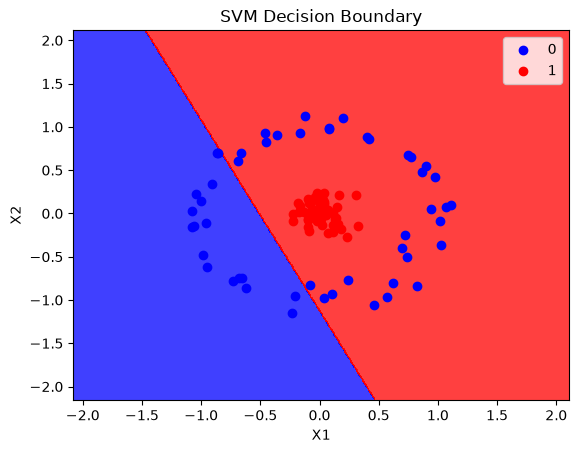

In [31]:
plot_decision_boundary(X, y, classifier)

In [18]:
def plot_3d_plot(X, y):
    r = np.exp(-(X ** 2).sum(1))
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=100, cmap='bwr')
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.set_zlabel('y')
    return ax

<Axes3D: xlabel='X1', ylabel='X2', zlabel='y'>

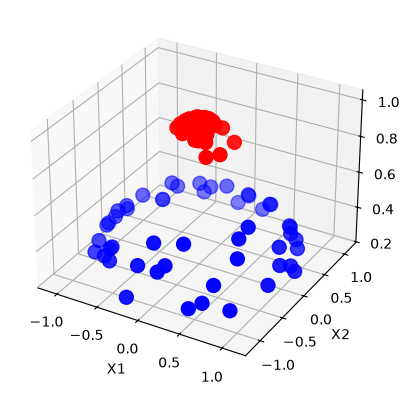

In [19]:
plot_3d_plot(X,y)

In [20]:
rbf_classifier = SVC(kernel="rbf")
rbf_classifier.fit(X_train, y_train)
y_pred = rbf_classifier.predict(X_test)

In [21]:
accuracy_score(y_test, y_pred)

1.0

C:\Users\jaggi\AppData\Local\Temp\ipykernel_12116\3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


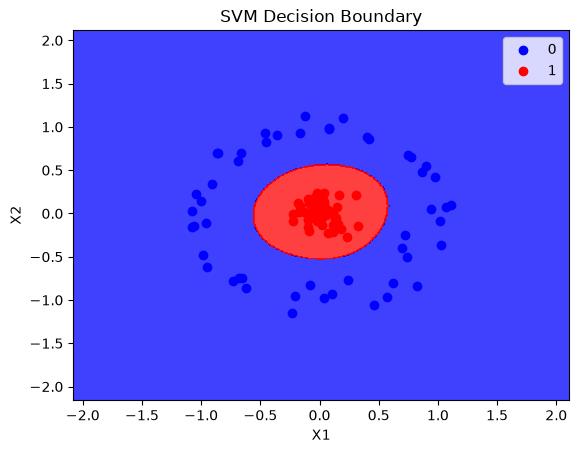

In [22]:
plot_decision_boundary(X, y, rbf_classifier)

In [23]:
poly_classifier = SVC(kernel="poly",degree=2)
poly_classifier.fit(X_train, y_train)
y_pred = poly_classifier.predict(X_test)

In [24]:
accuracy_score(y_test, y_pred)

1.0

C:\Users\jaggi\AppData\Local\Temp\ipykernel_12116\3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


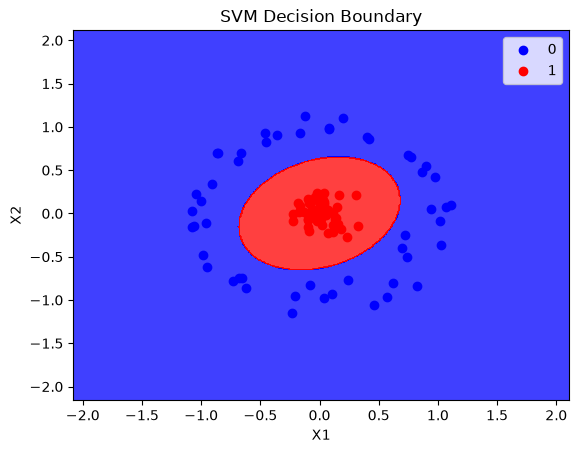

In [25]:
plot_decision_boundary(X, y, poly_classifier)

In [26]:
X

array([[ 8.38401999e-02,  9.86320522e-01],
       [ 6.92623488e-01, -3.99769182e-01],
       [ 1.39334372e-01, -5.10817268e-02],
       [ 1.16532847e-01, -4.62624469e-05],
       [ 1.13650625e-01, -1.32218477e-01],
       [-2.22675365e-01, -1.12805572e-02],
       [-9.26999538e-02,  1.26434325e-01],
       [-9.97894242e-01,  1.42008578e-01],
       [-6.76067477e-02,  5.19311251e-02],
       [ 7.30701739e-02, -2.27581722e-01],
       [-1.77026060e-01,  1.95373582e-02],
       [ 7.69582755e-01,  6.53334596e-01],
       [-7.30308437e-01, -7.76899975e-01],
       [ 1.10984147e+00,  9.19886449e-02],
       [-8.28298550e-02,  1.17209304e-01],
       [-9.46719939e-01, -6.23519843e-01],
       [-6.28642187e-02, -4.47844227e-02],
       [-1.67259648e-01,  8.91326755e-02],
       [-4.56942953e-01,  9.34974371e-01],
       [-8.31770205e-02, -3.70439083e-02],
       [-8.94983180e-02, -1.98921959e-01],
       [-1.35164159e-01,  1.26568318e-02],
       [ 8.64429224e-01,  4.74383290e-01],
       [ 1.

In [27]:
np.exp(-(X**2)).sum(1)

array([1.37100791, 1.47125327, 1.97816723, 1.98651188, 1.96983679,
       1.95149767, 1.97558499, 1.34946595, 1.99274655, 1.94419996,
       1.96876609, 1.20564122, 1.13349012, 1.28335586, 1.97951861,
       1.08597089, 1.99405225, 1.96449875, 1.22876529, 1.99173415,
       1.95322476, 1.98173634, 1.27215776, 1.25926237, 1.28346197,
       1.39757225, 1.34698165, 1.960911  , 1.99730346, 1.35719126,
       1.3165412 , 1.99654323, 1.13712652, 1.99863295, 1.32298284,
       1.99614501, 1.26720094, 1.08941359, 1.08993317, 1.31363614,
       1.32936068, 1.93504956, 1.38679405, 1.94494682, 1.16198746,
       1.99585702, 1.32027567, 1.3537986 , 1.95959885, 1.99414921,
       1.99887136, 1.22793375, 1.96163227, 1.20431086, 1.94488403,
       1.93039433, 1.49678982, 1.95263894, 1.87774426, 1.20487824,
       1.87867156, 1.97657261, 1.96195812, 1.94239466, 1.98156554,
       1.26064689, 1.99896484, 1.31214434, 1.20988044, 1.96022713,
       1.98019331, 1.20429739, 1.31254125, 1.19185929, 1.41354

In [28]:
X_new=np.exp(-(X**2))

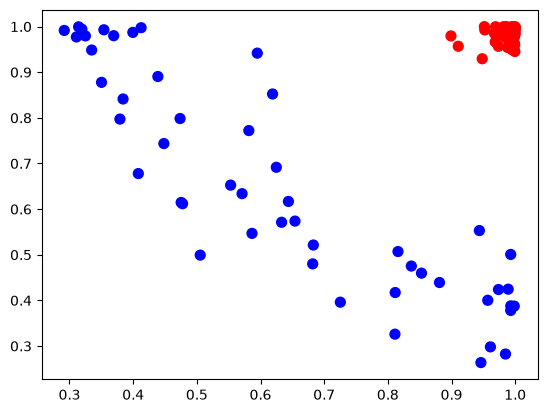

In [29]:
plt.scatter(X_new[:, 0], X_new[:, 1], c=y, s=50, cmap='bwr')